# Spam/Ham Classification Using NLTK, Lemmatization, BoW, TF-IDF and Naive Bayes

- `ham = 0`
- `spam = 1`
- Compare Bag of Words (BoW) and TF-IDF with `MultinomialNB`.


## 1. Import libraries and load the dataset

In [1]:
import re
import pandas as pd
import nltk

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

import matplotlib.pyplot as plt

# Download the NLTK resources required by this notebook
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\USER\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\USER\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\USER\AppData\Roaming\nltk_data...


True

In [2]:
DATA_PATH = 'SpamClassifier-master/smsspamcollection/SMSSpamClassifier.txt'

messages = pd.read_csv(
    DATA_PATH,
    sep='\t',
    names=['label', 'message'],
    encoding='utf-8'
)

# Basic checks
print("Dataset shape:", messages.shape)
print(messages.head())
print("\\nLabel counts:")
print(messages['label'].value_counts())


Dataset shape: (5572, 2)
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
\nLabel counts:
label
ham     4825
spam     747
Name: count, dtype: int64


## 2. Clean messages and apply lemmatization

In [3]:
# Initialize the lemmatizer and load stopwords once
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def preprocess_message(message):
    # Keep letters only, convert to lowercase, and tokenize
    review = re.sub(r'[^a-zA-Z]', ' ', str(message)).lower()
    words = review.split()

    # Remove stopwords and lemmatize each remaining word
    words = [
        lemmatizer.lemmatize(word)
        for word in words
        if word not in stop_words
    ]

    return ' '.join(words)

# Create the processed text corpus
corpus = messages['message'].apply(preprocess_message).tolist()

print("Original message:", messages['message'].iloc[0])
print("Processed message:", corpus[0])


Original message: Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...
Processed message: go jurong point crazy available bugis n great world la e buffet cine got amore wat


## 3. Encode the target labels

In [4]:
# Use one target value per message: ham = 0, spam = 1
y = messages['label'].map({'ham': 0, 'spam': 1})

# Stop early if the dataset contains an unexpected label
if y.isna().any():
    unexpected = messages.loc[y.isna(), 'label'].unique()
    raise ValueError(f"Unexpected label(s) found: {unexpected}")

y = y.astype('int64')

print("Target shape:", y.shape)
print(y.value_counts().rename(index={0: 'ham (0)', 1: 'spam (1)'}))


Target shape: (5572,)
label
ham (0)     4825
spam (1)     747
Name: count, dtype: int64


## 4. Split the data into training and testing sets

In [5]:
# Split before fitting vectorizers to prevent test data from influencing the vocabulary
X_train_text, X_test_text, y_train, y_test = train_test_split(
    corpus,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training messages:", len(X_train_text))
print("Testing messages:", len(X_test_text))
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)


Training messages: 4457
Testing messages: 1115
y_train shape: (4457,)
y_test shape: (1115,)


## 5. Bag of Words (BoW) features

In [6]:
cv = CountVectorizer(max_features=2500, ngram_range=(1, 2))

# Fit only on training messages; transform test messages using the same vocabulary
X_train_bow = cv.fit_transform(X_train_text)
X_test_bow = cv.transform(X_test_text)

print("X_train_bow shape:", X_train_bow.shape)
print("X_test_bow shape:", X_test_bow.shape)
print("Example vocabulary items:", list(cv.vocabulary_.items())[:10])


X_train_bow shape: (4457, 2500)
X_test_bow shape: (1115, 2500)
Example vocabulary items: [('guy', np.int64(882)), ('close', np.int64(356)), ('please', np.int64(1583)), ('come', np.int64(382)), ('town', np.int64(2163)), ('important', np.int64(1015)), ('moro', np.int64(1370)), ('ok', np.int64(1483)), ('knw', np.int64(1106)), ('tat', np.int64(2049))]


## 6. Train and evaluate the BoW Naive Bayes model

BoW Accuracy: 0.9811659192825112
\nBoW Classification Report:
              precision    recall  f1-score   support

         Ham       0.99      0.99      0.99       966
        Spam       0.95      0.91      0.93       149

    accuracy                           0.98      1115
   macro avg       0.97      0.95      0.96      1115
weighted avg       0.98      0.98      0.98      1115



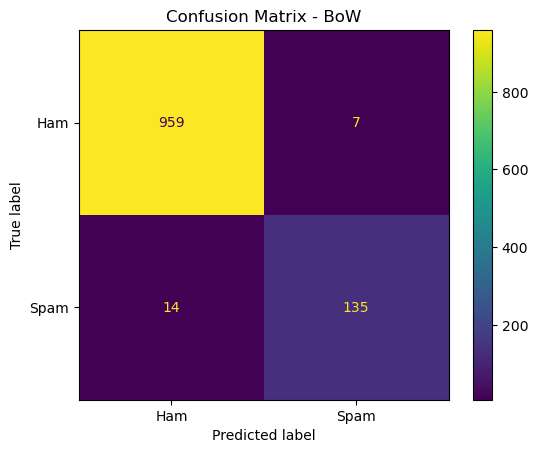

In [7]:
spam_detect_model = MultinomialNB()
spam_detect_model.fit(X_train_bow, y_train)

y_pred_bow = spam_detect_model.predict(X_test_bow)

print("BoW Accuracy:", accuracy_score(y_test, y_pred_bow))
print("\\nBoW Classification Report:")
print(classification_report(
    y_test,
    y_pred_bow,
    labels=[0, 1],
    target_names=['Ham', 'Spam'],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_bow,
    labels=[0, 1],
    display_labels=['Ham', 'Spam'],
    values_format='d'
)
plt.title('Confusion Matrix - BoW')
plt.show()


## 7. TF-IDF features

In [8]:
tv = TfidfVectorizer(max_features=2500, ngram_range=(1, 2))

# Fit only on training messages; transform test messages using the same vocabulary
X_train_tfidf = tv.fit_transform(X_train_text)
X_test_tfidf = tv.transform(X_test_text)

print("X_train_tfidf shape:", X_train_tfidf.shape)
print("X_test_tfidf shape:", X_test_tfidf.shape)
print("Example vocabulary items:", list(tv.vocabulary_.items())[:10])


X_train_tfidf shape: (4457, 2500)
X_test_tfidf shape: (1115, 2500)
Example vocabulary items: [('guy', np.int64(882)), ('close', np.int64(356)), ('please', np.int64(1583)), ('come', np.int64(382)), ('town', np.int64(2163)), ('important', np.int64(1015)), ('moro', np.int64(1370)), ('ok', np.int64(1483)), ('knw', np.int64(1106)), ('tat', np.int64(2049))]


## 8. Train and evaluate the TF-IDF Naive Bayes model

TF-IDF Accuracy: 0.9757847533632287
\nTF-IDF Classification Report:
              precision    recall  f1-score   support

         Ham       0.97      1.00      0.99       966
        Spam       0.98      0.83      0.90       149

    accuracy                           0.98      1115
   macro avg       0.98      0.92      0.94      1115
weighted avg       0.98      0.98      0.97      1115



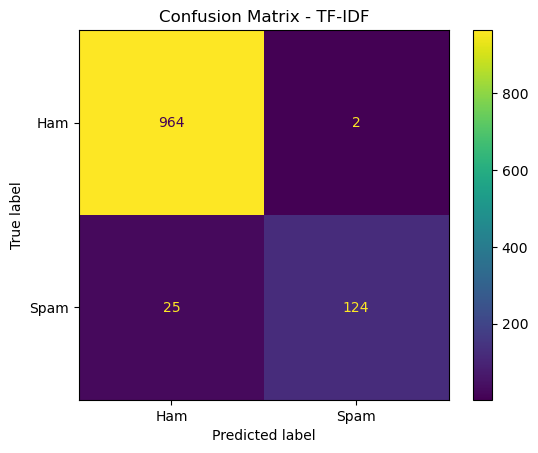

In [9]:
spam_tfidf_model = MultinomialNB()
spam_tfidf_model.fit(X_train_tfidf, y_train)

y_pred_tfidf = spam_tfidf_model.predict(X_test_tfidf)

print("TF-IDF Accuracy:", accuracy_score(y_test, y_pred_tfidf))
print("\\nTF-IDF Classification Report:")
print(classification_report(
    y_test,
    y_pred_tfidf,
    labels=[0, 1],
    target_names=['Ham', 'Spam'],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tfidf,
    labels=[0, 1],
    display_labels=['Ham', 'Spam'],
    values_format='d'
)
plt.title('Confusion Matrix - TF-IDF')
plt.show()


## 9. Compare both models

In [10]:
results = pd.DataFrame({
    'Model': ['Bag of Words + MultinomialNB', 'TF-IDF + MultinomialNB'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_bow),
        accuracy_score(y_test, y_pred_tfidf)
    ]
})

print(results.sort_values('Accuracy', ascending=False).to_string(index=False))


                       Model  Accuracy
Bag of Words + MultinomialNB  0.981166
      TF-IDF + MultinomialNB  0.975785


## 10. Test the trained TF-IDF model on a new message

In [11]:
def predict_spam_ham(message):
    cleaned_message = preprocess_message(message)
    message_features = tv.transform([cleaned_message])
    prediction = spam_tfidf_model.predict(message_features)[0]
    label = 'Spam' if prediction == 1 else 'Ham'
    return label

print(predict_spam_ham("Congratulations! You have won a free prize. Call now!"))
print(predict_spam_ham("Hey, are we still meeting for lunch today?"))


Spam
Ham
